### Lấy mẫu ngẫu nhiên từ dataset `loan.csv`

Dưới đây là list các cách phổ biến dùng để lấy mẫu dữ liệu từ cơ bản cho các dataset nhỏ, đến các công cụ thường được các Data Scientist dùng khi đọc dataset cực lớn.

1. `pd.read_csv()`      đọc toàn bộ dữ liệu vào RAM, phù hợp với dataset nhỏ hoặc vừa.
2. `df.sample()`        dùng để lấy mẫu ngẫu nhiên khi đã có `df`, thường được dùng với `pd.read_csv()`.
3. `chunksize`          tiết kiệm RAM bằng cách đọc dữ liệu theo từng phần (chunk).
4. `Reservoir Sampling` lấy mẫu ngẫu nhiên chuẩn trên các dataset rất lớn mà không cần lưu toàn bộ dữ liệu trong bộ nhớ.
5. `DuckDB / Polars`    công cụ xử lý dữ liệu lớn với hiệu năng cao.
6. `Spark`              xử lý dữ liệu cực lớn trên hệ thống phân tán.

Trong bài này vì dataset `loan.csv` có kích thước khoảng 1gb nên dùng `pd.read_csv` và `df.sample` là vừa đủ.

In [29]:
import pandas as pd

df = pd.read_csv("../../loan.csv")
df_sample = df.sample(n=100000, random_state=2412)

C:\Users\bphuy\AppData\Local\Temp\ipykernel_19408\3070972143.py:3: DtypeWarning: Columns (19: desc, 47: next_pymnt_d, 55: verification_status_joint, 112: sec_app_earliest_cr_line, 123: hardship_type, 124: hardship_reason, 125: hardship_status, 128: hardship_start_date, 129: hardship_end_date, 130: payment_plan_start_date, 133: hardship_loan_status, 139: debt_settlement_flag_date, 140: settlement_status, 141: settlement_date) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../../loan.csv")


### EDA - Exploratory Data Analysis

1. Xem dữ liệu (`head()`, `tail()`)
2. Xem kích thước dataset (`shape`)
3. Xem kiểu dữ liệu (`info()`)
4. Thống kê tỷ lệ missing
5. Xem các cột hằng số hoặc có quá ít giá trị unique
6. Phân loại cột thành `numerical` và `categorical`
7. Xác định biến mục tiêu (target)
8. Chọn các cột quan trọng để phân tích
9. Quan sát biểu đồ:
    - Histogram
    - Boxplot (đối với numerical)
10. Phân tích các cột `categorical`

### Data Preprocessing
11. Xử lý dữ liệu thiếu (missing values)
12. Xử lý outlier (`log1p`)



##### 1. `Xem dữ liệu`

In [30]:
display(df_sample.head())
display(df_sample.tail())

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
1590661,NaN,NaN,16000,16000,16000.0,36 months,10.42,519.44,B,B3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1609217,NaN,NaN,6000,6000,6000.0,36 months,15.05,208.14,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
902066,NaN,NaN,15000,15000,15000.0,36 months,12.74,503.54,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1030445,NaN,NaN,27000,27000,27000.0,36 months,5.32,813.10,A,A1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1265339,NaN,NaN,1600,1600,1600.0,36 months,15.61,55.95,D,D1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
207319,NaN,NaN,12500,12500,12500.0,36 months,6.11,380.90,A,A1,...,NaN,NaN,DirectPay,N,NaN,NaN,NaN,NaN,NaN,NaN
1585582,NaN,NaN,12000,12000,12000.0,60 months,15.05,285.80,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1709142,NaN,NaN,6000,6000,6000.0,36 months,20.20,223.60,D,D5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
302053,NaN,NaN,40000,40000,40000.0,60 months,15.49,961.92,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2170166,NaN,NaN,15000,15000,15000.0,60 months,10.42,321.82,B,B3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


##### 2. `Xem kích thước`

In [ ]:
df_sample.shape

(100000, 145)

: 

##### 3. `Xem kiểu dữ liệu`

In [4]:
df_sample.info()

<class 'pandas.DataFrame'>
Index: 100000 entries, 1590661 to 2170166
Columns: 145 entries, id to settlement_term
dtypes: float64(105), int64(4), str(36)
memory usage: 111.4 MB


##### 4. ` Thống kê missing values`

In [5]:
missing_stats = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": round(df.isna().mean() * 100, 2)
})

missing_stats = missing_stats.sort_values(
    by="missing_pct",
    ascending=False
)

missing_stats.head(20)

,missing_count,missing_pct
id,2260668,100.00
member_id,2260668,100.00
url,2260668,100.00
orig_projected_additional_accrued_interest,2252242,99.63
hardship_amount,2250055,99.53
hardship_dpd,2250055,99.53
hardship_loan_status,2250055,99.53
deferral_term,2250055,99.53
hardship_end_date,2250055,99.53
hardship_status,2250055,99.53


#### Vì số cột có tỉ lệ missing cao (>90%) tương đối nhiều nên xóa hết
Xem các cột có missing value >70%

In [6]:
cols_to_drop = missing_stats[
    missing_stats["missing_pct"] > 70
]

print(f"Số cột sẽ bị xóa: {len(cols_to_drop)}")
display(cols_to_drop)

Số cột sẽ bị xóa: 41


,missing_count,missing_pct
id,2260668,100.00
member_id,2260668,100.00
url,2260668,100.00
orig_projected_additional_accrued_interest,2252242,99.63
hardship_amount,2250055,99.53
hardship_dpd,2250055,99.53
hardship_loan_status,2250055,99.53
deferral_term,2250055,99.53
hardship_end_date,2250055,99.53
hardship_status,2250055,99.53


Xóa các cột đó

In [7]:
df_sample=df_sample.drop(columns=cols_to_drop.index)

#### 5. ` Thống kê unique `
- Thống kê số lượng giá trị unique của từng cột.
- Loại bỏ các cột hằng số (unique = 1).
- Xem xét các cột có số lượng unique rất thấp hoặc quá cao (ID, URL, ...) tuy nhiên hông nên tùy ý xóa các cột unique rất thấp hoặc quá cao nếu chưa biết rõ nghiệp vụ, do đó trong bài này chỉ xóa các cột hằng số.

In [8]:
unique_stats = pd.DataFrame({
    "unique_count": df_sample.nunique()
})

unique_stats.sort_values(
    by="unique_count"
).head(20)

,unique_count
policy_code,1
term,2
initial_list_status,2
pymnt_plan,2
application_type,2
disbursement_method,2
hardship_flag,2
debt_settlement_flag,2
verification_status,3
num_tl_120dpd_2m,4


In [9]:
constant_cols = unique_stats[
    unique_stats["unique_count"] == 1
].index

constant_cols

Index(['policy_code'], dtype='str')

In [10]:
df_sample = df_sample.drop(columns=constant_cols)

##### 6. Phân loại cột thành `numerical` và `categorical`

In [11]:
num_cols = df_sample.select_dtypes(include="number").columns
cat_cols = df_sample.select_dtypes(exclude="number").columns

print(f"Numerical columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")

Numerical columns: 80
Categorical columns: 23


Xem danh sách cột num & cột cat để rà lại và chỉnh sửa các kiểu dữ liệu

In [12]:
list(num_cols)

['loan_amnt',
 'funded_amnt',
 'funded_amnt_inv',
 'int_rate',
 'installment',
 'annual_inc',
 'dti',
 'delinq_2yrs',
 'inq_last_6mths',
 'mths_since_last_delinq',
 'open_acc',
 'pub_rec',
 'revol_bal',
 'revol_util',
 'total_acc',
 'out_prncp',
 'out_prncp_inv',
 'total_pymnt',
 'total_pymnt_inv',
 'total_rec_prncp',
 'total_rec_int',
 'total_rec_late_fee',
 'recoveries',
 'collection_recovery_fee',
 'last_pymnt_amnt',
 'collections_12_mths_ex_med',
 'acc_now_delinq',
 'tot_coll_amt',
 'tot_cur_bal',
 'open_acc_6m',
 'open_act_il',
 'open_il_12m',
 'open_il_24m',
 'mths_since_rcnt_il',
 'total_bal_il',
 'il_util',
 'open_rv_12m',
 'open_rv_24m',
 'max_bal_bc',
 'all_util',
 'total_rev_hi_lim',
 'inq_fi',
 'total_cu_tl',
 'inq_last_12m',
 'acc_open_past_24mths',
 'avg_cur_bal',
 'bc_open_to_buy',
 'bc_util',
 'chargeoff_within_12_mths',
 'delinq_amnt',
 'mo_sin_old_il_acct',
 'mo_sin_old_rev_tl_op',
 'mo_sin_rcnt_rev_tl_op',
 'mo_sin_rcnt_tl',
 'mort_acc',
 'mths_since_recent_bc',
 'mt

In [13]:
list(cat_cols)

['term',
 'grade',
 'sub_grade',
 'emp_title',
 'emp_length',
 'home_ownership',
 'verification_status',
 'issue_d',
 'loan_status',
 'pymnt_plan',
 'purpose',
 'title',
 'zip_code',
 'addr_state',
 'earliest_cr_line',
 'initial_list_status',
 'last_pymnt_d',
 'next_pymnt_d',
 'last_credit_pull_d',
 'application_type',
 'hardship_flag',
 'disbursement_method',
 'debt_settlement_flag']

Phát hiện các cột:
    "issue_d",
    "earliest_cr_line",
    "last_pymnt_d",
    "last_credit_pull_d"
là cột date chứ kh phải cat, nên chúng ta sẽ chuyển đổi

In [14]:
date_cols = [
    "issue_d",
    "earliest_cr_line",
    "last_pymnt_d",
    "last_credit_pull_d"
]

for col in date_cols:
    df_sample[col] = pd.to_datetime(
        df_sample[col],
        errors="coerce"
    )

C:\Users\bphuy\AppData\Local\Temp\ipykernel_19408\2393467789.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample[col] = pd.to_datetime(
C:\Users\bphuy\AppData\Local\Temp\ipykernel_19408\2393467789.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample[col] = pd.to_datetime(
C:\Users\bphuy\AppData\Local\Temp\ipykernel_19408\2393467789.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample[col] = pd.to_datetime(
C:\Users\bphuy\AppData\Local\Temp\ipykernel_19408\2393467789.py:9: UserWarning: Could not infer format, so each element will be parsed individ

##### 7. Xác định biến mục tiêu (target)
Cần trả lời:
- Lãi suất nằm trong khoảng nào?
- Có bị lệch không?
- Có outlier không?

In [15]:
target = "int_rate"
df_sample["int_rate"].describe()

count    100000.000000
mean         13.080296
std           4.815213
min           5.310000
25%           9.490000
50%          12.620000
75%          15.990000
max          30.990000
Name: int_rate, dtype: float64

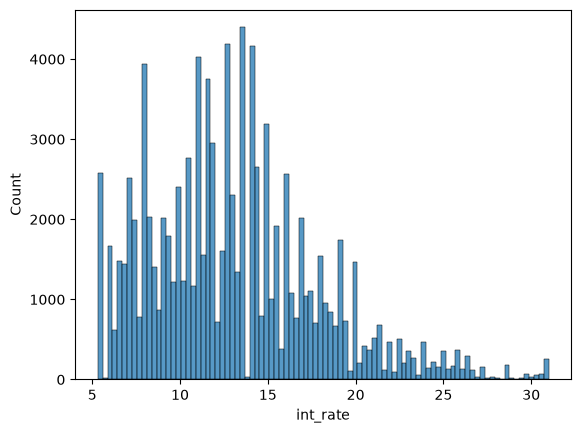

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_sample["int_rate"])

plt.show()

- Lãi suất khoản vay dao động từ 5.31% đến 30.99%.
- 50% khoản vay có lãi suất nằm trong khoảng từ 9.70% đến 15.99%.
- Phân phối có xu hướng lệch phải, cho thấy phần lớn khách hàng có lãi suất trung bình và chỉ một số ít khách hàng có lãi suất rất cao.
- Theo quy tắc IQR, tồn tại một số giá trị outlier ở phía trên. Tuy nhiên các giá trị này vẫn nằm trong phạm vi hợp lý của lãi suất vay.
- Không suất hiện các lỗi nhập liệu như 300%, -999%
---

##### 8. Chọn các feature quan trọng dựa trên
1. Correlation cho các cột số với biến mục tiêu

2. Chọn thêm các cột categorical có ý nghĩa nghiệp vụ: term, grade, sub_grade, verifcation_status, home_ownership

In [17]:
corr_with_target = (
    df_sample[num_cols]
    .corr()["int_rate"]
    .abs()
    .sort_values(ascending=False)
)

corr_with_target.head(20)

int_rate                 1.000000
total_rec_int            0.409145
bc_open_to_buy           0.293514
all_util                 0.286559
bc_util                  0.276313
percent_bc_gt_75         0.272896
revol_util               0.262531
total_bc_limit           0.229752
inq_last_6mths           0.189279
total_rev_hi_lim         0.184720
num_tl_op_past_12m       0.181674
inq_last_12m             0.171454
acc_open_past_24mths     0.170379
open_il_12m              0.157468
open_il_24m              0.152039
mths_since_recent_inq    0.149902
il_util                  0.144780
recoveries               0.140508
inq_fi                   0.137862
mo_sin_old_rev_tl_op     0.136597
Name: int_rate, dtype: float64

Các numerical feature được chọn gồm:
- `total_rec_int`
- `all_util`
- `bc_open_to_buy`
- `percent_bc_gt_75`
- `bc_util`

Đây là các feature có độ tương quan tương đối cao với biến mục tiêu `int_rate`.

Ngoài ra, một số feature cũng được lựa chọn dựa trên ý nghĩa nghiệp vụ:

- `annual_inc`
- `loan_amnt`
- `dti`

Kết hợp với các categorical feature:

- `term`
- `grade`
- `sub_grade`
- `verification_status`
- `home_ownership`

Loại bỏ các cột mặc dù có độ tương quan cao nhưng có khả năng gây data leakage:
`total_rec_int`.

In [18]:
# Numerical features
important_num_cols = [
    "all_util",
    "bc_open_to_buy",
    "percent_bc_gt_75",
    "bc_util",
    "annual_inc",
    "loan_amnt",
    "dti"
]
# Categorical features
important_cat_cols = [
    "term",
    "grade",
    "sub_grade",
    "verification_status",
    "home_ownership"
]
eda_cols = important_num_cols + important_cat_cols + [target]

df_eda = df_sample[eda_cols]

df_eda.head()

,all_util,bc_open_to_buy,percent_bc_gt_75,bc_util,annual_inc,loan_amnt,dti,term,grade,sub_grade,verification_status,home_ownership,int_rate
1590661,73.0,8042.0,50.0,57.9,66000.0,16000,18.62,36 months,B,B3,Verified,MORTGAGE,10.42
1609217,83.0,532.0,100.0,83.4,56000.0,6000,11.74,36 months,C,C4,Not Verified,OWN,15.05
902066,52.0,23226.0,22.2,52.0,70000.0,15000,12.63,36 months,C,C1,Source Verified,OWN,12.74
1030445,NaN,32511.0,33.3,44.5,100000.0,27000,10.63,36 months,A,A1,Not Verified,MORTGAGE,5.32
1265339,NaN,2111.0,0.0,8.2,45000.0,1600,15.23,36 months,D,D1,Verified,MORTGAGE,15.61


##### 9. Quan sát biểu đồ:
    - Histogram

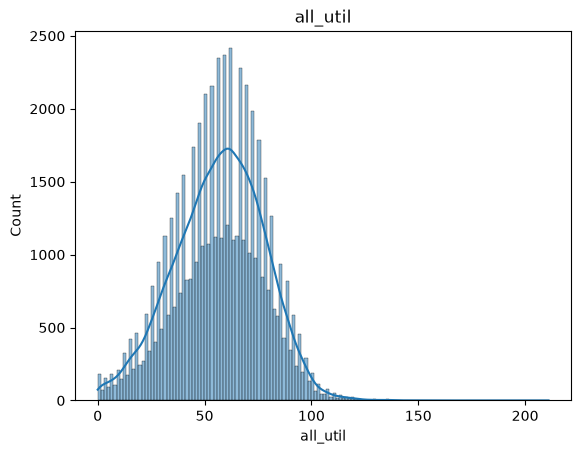

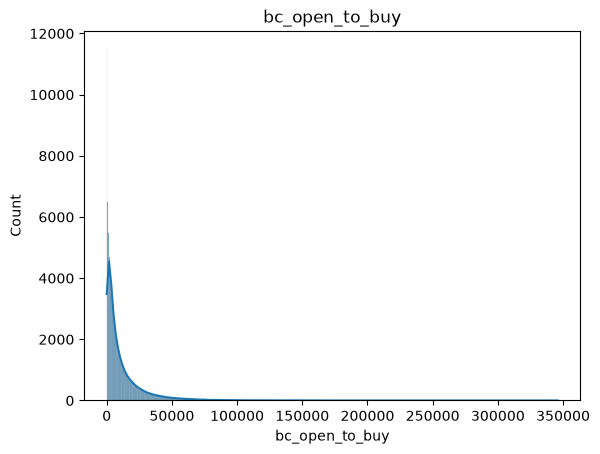

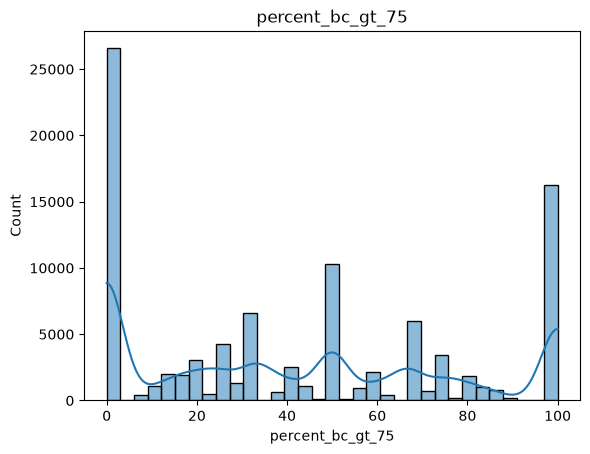

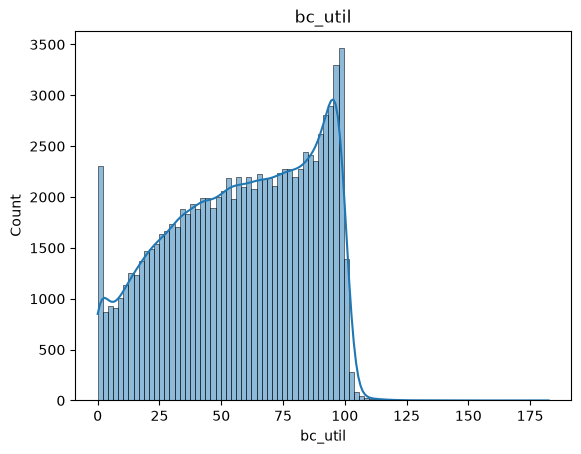

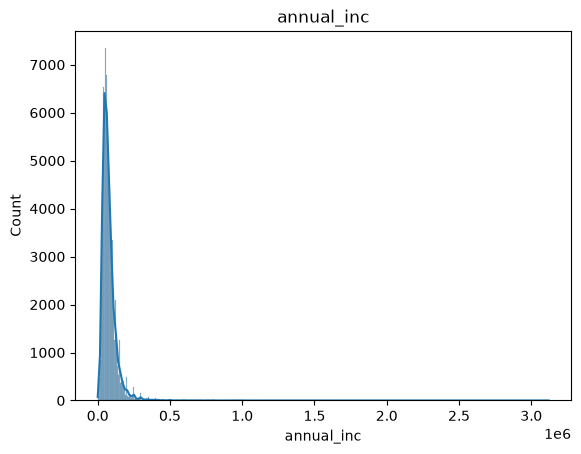

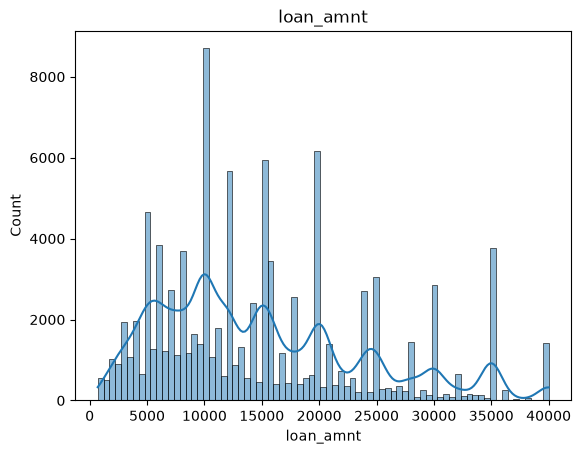

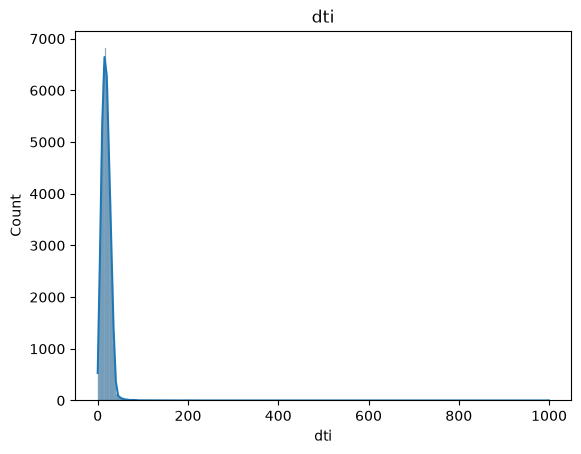

In [19]:
for col in important_num_cols:
    sns.histplot(df_eda[col], kde=True)
    plt.title(col)
    plt.show()

    - Boxplot (đối với numerical)

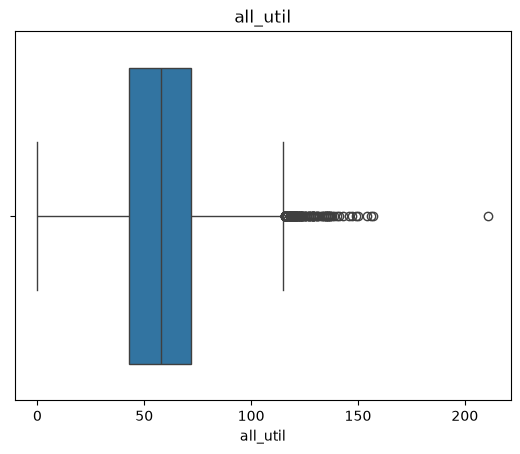

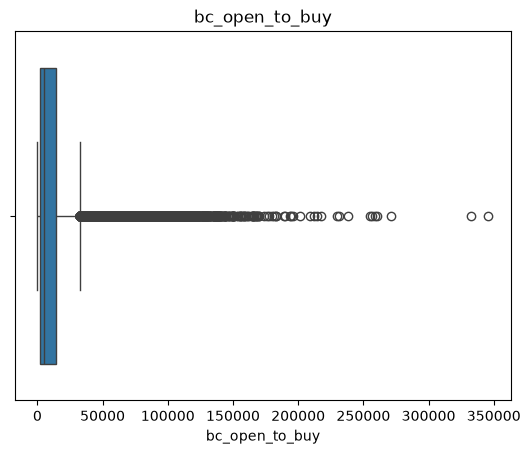

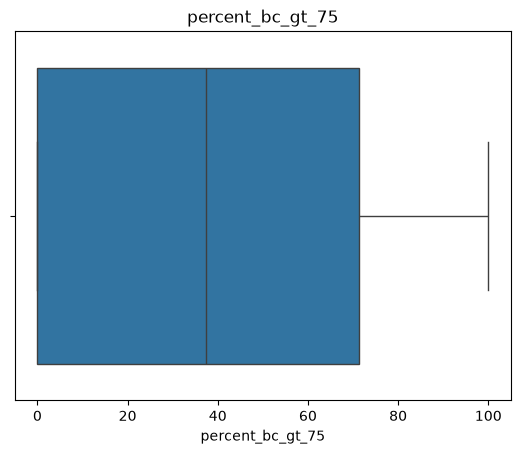

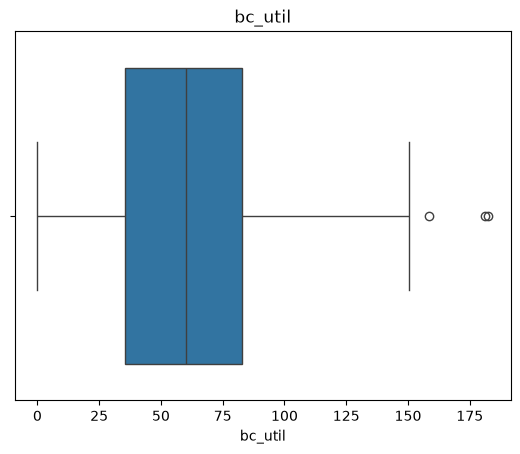

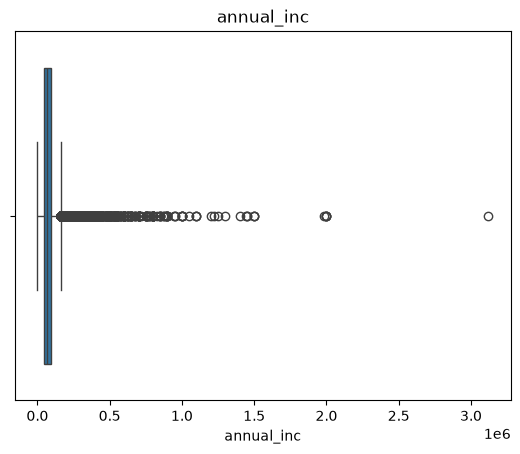

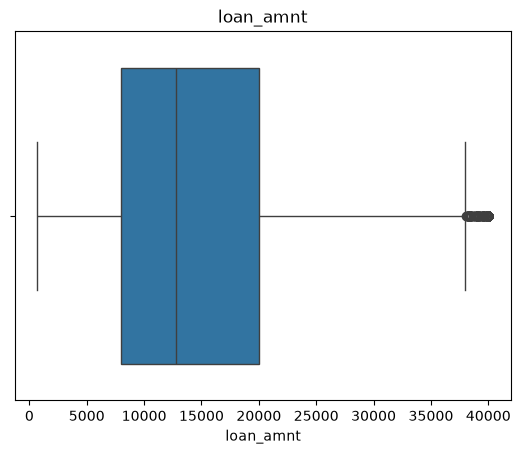

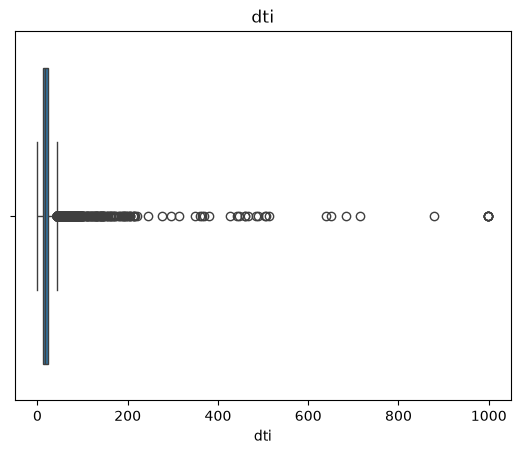

In [20]:
for col in important_num_cols:
    sns.boxplot(x=df_eda[col])
    plt.title(col)
    plt.show()

##### 10. Phân tích các cột `categorical`

In [21]:
for col in important_cat_cols:
    display(
        df_eda.groupby(col)["int_rate"]
              .mean()
              .sort_values()
    )

term
36 months    11.943946
60 months    15.910126
Name: int_rate, dtype: float64

grade
A     7.072360
B    10.668872
C    14.131170
D    18.132038
E    21.793479
F    25.384168
G    28.079325
Name: int_rate, dtype: float64

sub_grade
A1     5.592683
A2     6.558197
A3     7.094130
A4     7.560356
A5     8.197321
B1     9.059324
B2     9.978922
B3    10.701234
B4    11.357076
B5    12.015640
C1    12.779105
C2    13.533009
C3    14.105971
C4    14.884460
C5    15.765838
D1    16.666129
D2    17.625003
D3    18.365515
D4    19.075099
D5    20.042192
E1    20.288863
E2    20.996332
E3    21.752561
E4    22.788204
E5    24.040786
F1    24.541412
F2    24.894425
F3    25.897114
F4    26.291304
F5    26.781005
G2    27.496423
G1    27.737981
G4    28.611000
G5    28.777681
G3    28.813846
Name: int_rate, dtype: float64

verification_status
Not Verified       11.592287
Source Verified    13.199218
Verified           14.687391
Name: int_rate, dtype: float64

home_ownership
ANY         12.480417
MORTGAGE    12.742101
OWN         13.036311
RENT        13.509601
NONE        15.313333
OTHER       16.602000
Name: int_rate, dtype: float64

##### 11. Xử lý missing value

In [22]:
missing_stats = pd.DataFrame({
    "missing_count": df_eda.isna().sum(),
    "missing_pct": round(df_eda.isna().mean() * 100, 2)
})

missing_stats = missing_stats.sort_values(
    by="missing_pct",
    ascending=False
)

display(missing_stats)

,missing_count,missing_pct
all_util,38334,38.33
bc_util,3393,3.39
percent_bc_gt_75,3357,3.36
bc_open_to_buy,3336,3.34
dti,75,0.08
annual_inc,0,0.00
loan_amnt,0,0.00
term,0,0.00
grade,0,0.00
sub_grade,0,0.00


Cột all_util thiếu khá nhiều, quan sát histogram và boxplot thấy được cột này có phân phối gần chuẩn và ít outlier, median cũng gần bằng mean nên dùng mean hay median đều hợp lý

Cột bc_open_to_buy, lệch phải nặng nên kh dùng mean

Cột percent_bc_gt_75 và bc_util, không chuẩn => dùng median cho an toàn

In [23]:
# all_util
df_eda["all_util"] = (
    df_eda["all_util"]
    .fillna(df_eda["all_util"].mean())
)

# các cột lệch hoặc có outlier
for col in [
    "bc_open_to_buy",
    "percent_bc_gt_75",
    "bc_util",
    "dti"
]:
    df_eda[col] = (
        df_eda[col]
        .fillna(df_eda[col].median())
    )

##### 12. Xử lý outlier

In [24]:
for col in important_num_cols:
    Q1 = df_eda[col].quantile(0.25)
    Q3 = df_eda[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_eda[
        (df_eda[col] < lower) |
        (df_eda[col] > upper)
    ]

    print(
        f"{col}: {len(outliers)} outliers "
        f"({round(len(outliers)/len(df_eda)*100,2)}%)"
    )

all_util: 20269 outliers (20.27%)
bc_open_to_buy: 8580 outliers (8.58%)
percent_bc_gt_75: 0 outliers (0.0%)
bc_util: 3 outliers (0.0%)
annual_inc: 4818 outliers (4.82%)
loan_amnt: 1484 outliers (1.48%)
dti: 913 outliers (0.91%)


Cột `all_util` có tỷ lệ outlier khá cao (21.1%) theo phương pháp IQR. Tuy nhiên khi quan sát histogram và boxplot, có thể thấy dữ liệu vẫn phân bố tương đối tự nhiên và không xuất hiện các giá trị bất thường về mặt nghiệp vụ. Do đó các outlier của cột này sẽ được giữ lại.

Các feature annual_inc và bc_open_to_buy có phân phối lệch phải và chứa nhiều giá trị lớn.

Sử dụng log transformation để giảm độ lệch của phân phối, giảm ảnh hưởng của outlier và giúp dữ liệu ổn định hơn cho mô hình.

Các cột `loan_amnt`, `dti`, `bc_util` và `percent_bc_gt_75` có số lượng outlier thấp hoặc không đáng kể, vì vậy không cần xử lý thêm ở bước này. 

In [25]:
import numpy as np

df_eda["bc_open_to_buy"] = np.log1p(
    df_eda["bc_open_to_buy"]
)

In [26]:
df_eda["annual_inc"] = np.log1p(
    df_eda["annual_inc"]
)

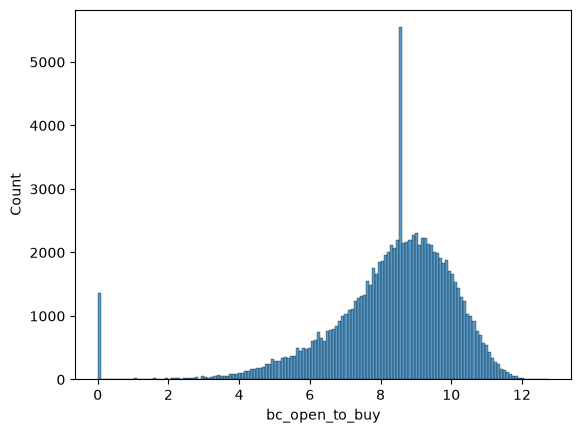

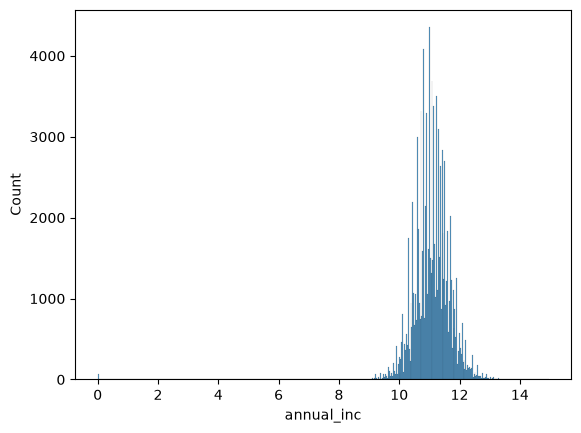

In [27]:
sns.histplot(df_eda["bc_open_to_buy"])
plt.show()

sns.histplot(df_eda["annual_inc"])
plt.show()

##### Save Preprocessed Dataset


In [28]:
df_eda.to_csv(
    "../data/loan_preprocessed.csv",
    index=False
)